In [25]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))
print(project_path/'data'/'df'/'test.df')

# My imports
from utils.utils import *

/home/syebes/lambda-ana/data/df/test.df


# Load files

In [26]:
# POT taken from preselection stage

lambda_pot = 1.428596135616784e+23
aurora_pot = 1.8018085197812987e+20

In [27]:
lambda_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/lambdaFransOutput.root"
aurora_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/devFransOutput.root"

frans_tdir = "FRANSProducer/fransTree"

In [28]:
lambda_tree = uproot.open(lambda_file)[frans_tdir]
aurora_tree = uproot.open(aurora_file)[frans_tdir]

In [33]:
branches = [
 'file_name',
 'event_id',
 'run_id',
 'subrun_id',
 'slice_id',
 'gen_index',
 'nu_pdg',
 #'nu_e0',
 #'nu_weight',
 'nu_int_mode',
 'nu_int_type',
 'nu_cc_nc',
 #'nu_target',
 #'nu_hit_nuc',
 #'nu_hit_quark',
 #'nu_w',
 #'nu_x',
 #'nu_y',
 #'nu_q_sqr',
 'gen_id',
 'gen_status_code',
 'gen_mother',
 'gen_pdg',
 'gen_mass',
 'gen_e0',
 'gen_start_x',
 'gen_start_y',
 'gen_start_z',
 'gen_p0_x',
 'gen_p0_y',
 'gen_p0_z',
 'n_protons',
 'n_neutrons',
 'n_pi0',
 'n_pip',
 'n_pim',
 'n_mup',
 'n_mum',
 'n_ep',
 'n_em',
 'n_lambda',
 'n_sigma0',
 'n_sigmap',
 'n_sigmam',
 'n_hyperon',
 # 'g4_id',
 # 'g4_mother',
 # 'g4_pdg',
 # 'g4_mass',
 # 'g4_e0',
 # 'g4_ef',
 # 'g4_tl',
 # 'g4_start_x',
 # 'g4_start_y',
 # 'g4_start_z',
 # 'g4_start_time_tick',
 # 'g4_start_channel_u',
 # 'g4_start_channel_v',
 # 'g4_start_channel_c',
 # 'g4_end_x',
 # 'g4_end_y',
 # 'g4_end_z',
 # 'g4_end_time_tick',
 # 'g4_end_channel_u',
 # 'g4_end_channel_v',
 # 'g4_end_channel_c',
 # 'g4_p0_x',
 # 'g4_p0_y',
 # 'g4_p0_z',
 # 'g4_pf_x',
 # 'g4_pf_y',
 # 'g4_pf_z',
 # 'g4_process',
 # 'g4_end_process',
 'true_gap',
 'has_lambda',
 'has_lambda_v',
 'is_lambda_signal',
 'slc_purity',
 'slc_completeness',
 'pre_is_clear_cosmic',
 'pre_nu_score',
 'pre_bcfm_score',
 'pre_is_fiducial',
 'pre_n_prim_pfps',
 'pre_n_prim_trks',
 'pre_n_prim_shwrs',
 'pre_n_trks_exit',
 'pre_max_gap',
 'pre_pass',
 'frans_n_origins',
 'frans_n_origins_mult1',
 'frans_n_origins_mult2',
 'frans_n_origins_gt3',
 'frans_n_origins_pair_one_two',
 'frans_n_unassoc_origins',
 'frans_n_unassoc_origins_mult1',
 'frans_n_unassoc_origins_mult2',
 'frans_n_unassoc_origins_mult3',
 'frans_succeed',
 'frans_n_angles',
 'frans_score',
 'frans_gap',
 'frans_n_hits',
 'frans_n_hits_trk1',
 'frans_n_hits_trk2',
 'frans_min_n_hits',
 'frans_n_hits_main',
 'frans_len_trk1',
 'frans_len_trk2',
 'frans_len_main',
 'frans_longest_is_main',
 'frans_covered_area',
 'frans_dirt_hits',
 'frans_dirt_hits_ratio',
 'frans_dirt_hits_wires',
 'frans_dirt_hits_wires_ratio',
 'frans_n_free_hits',
 'frans_n_unassoc_hits',
 'frans_n_max_dirt_unassoc_hits',
 'hyperon_vtx_x',
 'hyperon_vtx_y',
 'hyperon_vtx_z',
 'prim_lepton_vtx_x',
 'prim_lepton_vtx_y',
 'prim_lepton_vtx_z',
 'true_muon_in_fv',
 'true_muon_decay',
 'michel_vars_computed',
 'michel_n_muon_tracks',
 'michel_rss_ratio',
 'michel_angle_q80',
 'michel_drop_radius',
 'michel_n_blips',
 'michel_score']

In [34]:
lambda_df = pd.DataFrame(lambda_tree.arrays(branches, library="np", entry_stop=None))
aurora_df = pd.DataFrame(aurora_tree.arrays(branches, library="np", entry_stop=None))

In [ ]:
pot_3y = 7e20

lambda_scale = pot_3y / lambda_pot
aurora_scale = pot_3y / aurora_pot

aurora_sgnl_mask = (aurora_df.n_lambda > 0) | (aurora_df.n_sigma0 > 0)

lambda_df['scale'] = pot_3y / (lambda_pot + aurora_pot)
aurora_df['scale'] = aurora_scale
aurora_df.loc[aurora_sgnl_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot)

In [ ]:
df = pd.concat([lambda_df, aurora_df])

# Preselection

In [10]:
preselected_mask = df.pre_pass

pre_df = df[preselected_mask]

# Selection

In [16]:
import importlib
import utils.utils

importlib.reload(utils.utils)
from utils.utils import *

In [17]:
# =============
# Configuration
# =============


cuts_dict = {
    'N vertices pairs' : Cut('frans_n_angles','>=', 1, discrete=True),
    'Frans Score' : Cut('frans_score','>', 0.2),
    #'Contained angle' : Cut('frans_contained_phi','<', 2.5),
    #'Pz sign' : Cut('frans_pzsign', '==', 2),
    'N unassoc. origins' : Cut('frans_n_unassoc_origins','<', 1, discrete=True),
    'N unassoc. hits' : Cut('frans_n_max_dirt_unassoc_hits','<', 10),
}

palette = {
        "Signal":       "#2ecc71",
        "Nu background":   "#e74c3c",
        "Cosmics":     "#3498db",
}

categories = {
    "Signal" : ('is_lambda_signal', '==1'),
    "Cosmics":   ('gen_index', ">1"),
    "Nu background": ('gen_index', "==1"),
}


# Analysis configuration
ana_cfg = AnalysisConfig(
    categories = categories,
    cuts=cuts_dict,
    palette=palette,
)


# Analysis driver
driver = AnalysisDriver(pre_df, ana_cfg)

In [18]:
cp = driver.get_cuts_performance()

cp.style.format({
    "Signal" : "{:.0f}",
    "Sigma0" : "{:.0f}",
    "Cosmics" : "{:.2e}",
    "Nu background" : "{:.2e}",
    "Cut efficiency (%)": "{:.1f}",
    "Total efficiency (%)": "{:.1f}",
    "Purity (%)": "{:.3f}",
    "Bck rejection (%)": "{:.2f}",
})

,Stage,Cut value,Signal,Cosmics,Nu background,Cut efficiency (%),Total efficiency (%),Purity (%),Bck rejection (%)
0,Initial,[],78,1.41e+02,7.97e+03,100.0,100.0,0.946,0.00
1,N vertices pairs,1,78,1.41e+02,7.97e+03,100.0,100.0,0.946,0.00
2,Frans Score,0.2,48,1.70e+01,5.86e+02,62.0,62.0,7.385,92.58
3,N unassoc. origins,0,44,8.49e+00,2.80e+02,92.4,57.3,13.357,96.45
4,N unassoc. hits,10,38,4.35e+00,1.87e+02,86.7,49.7,16.744,97.64


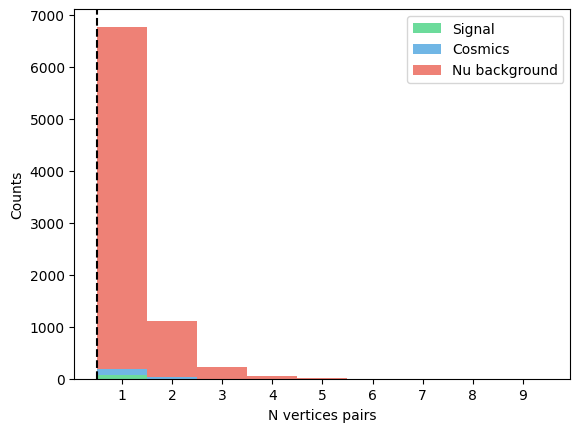

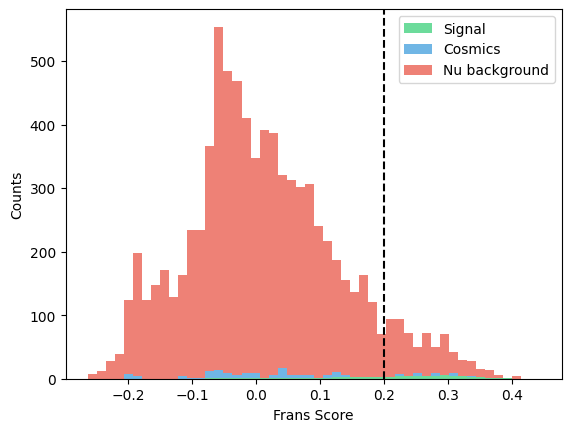

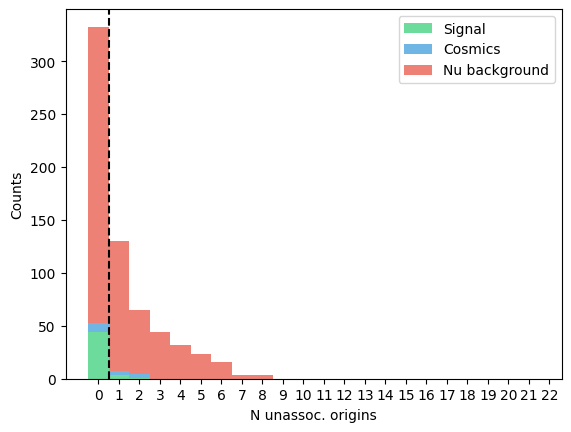

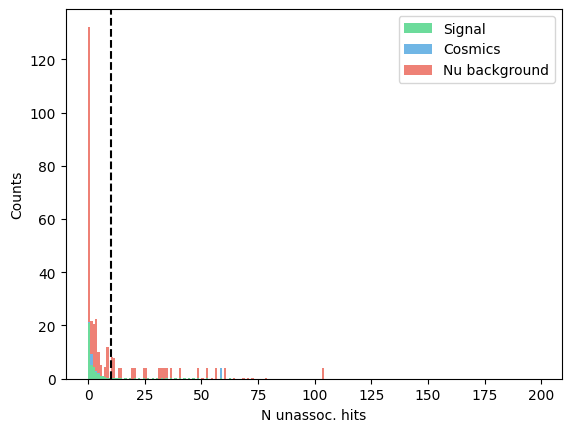

In [19]:
driver.plot_cuts(weights_col='scale', bins = 50)

# Preselection

Not needed with next production

In [ ]:
def apply_preselection(df):
    return ((~df.pre_is_clear_cosmic)
           & (df.pre_nu_score > 0.5)
           & (df.pre_bcfm_score > 0.04)
           & (df.pre_is_fiducial)
           & (df.pre_n_prim_pfps >= 2)
           & (df.pre_n_prim_pfps < 5)
           & (df.pre_n_prim_trks >= 0)
           & (df.pre_n_prim_trks < 4)
           & (df.pre_n_prim_shwrs >= 0)
           & (df.pre_n_prim_shwrs < 2)
           & (df.pre_n_trks_exit < 2)
           & (df.pre_max_gap > 1)) 

lambda_df['preselected'] = apply_preselection(lambda_df)

In [ ]:
lambda_df.groupby(["preselected", "pre_pass"])["scale"].sum()

In [ ]:
lambda_df[['preselected', 'pre_pass']].value_counts()

In [ ]:
aurora_df[['n_lambda','n_sigma0',]].value_counts()

In [ ]:
lambda_df.columns

In [ ]:
signal_mask = (lambda_df.is_lambda_signal == 1)

lambda_df[signal_mask].groupby(['event_id', 'run_id', 'subrun_id'])["scale"].first().sum()

In [ ]:
lambda_df.frans_score.value_counts()

In [ ]:
lambda_df[signal_mask].frans_n_angles.value_counts()